In [11]:
# Import Libraries and Load Data
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [12]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Load dataset
try:
    df.head()
    print("Using existing dataframe.")
except NameError:
    df = pd.read_csv("Karanda-Diabetic-Patients-Processed.csv")
    print("Data loaded successfully!")

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

print("\nDataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

# Find possible target columns
possible_targets = [
    'readmitted',
    'readmission',
    'readmission_status',
    'readmitted_status',
    'target',
    'outcome'
]

target_col = None

for col in df.columns:
    if col.lower() in [x.lower() for x in possible_targets]:
        target_col = col
        break

# If target wasn't found, display possible candidates
if target_col is None:
    print("\nERROR: Target column was not found.")

    print("\nColumns containing possible target keywords:")
    for col in df.columns:
        if any(word in col.lower()
               for word in ['readmit', 'readmission', 'target', 'outcome']):
            print(" -", col)

    raise ValueError(
        "Please identify the actual readmission/target column from the list above."
    )

print(f"\nUsing target column: '{target_col}'")

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# Copy features
X_encoded = X.copy()

# Encode categorical variables
le_dict = {}

categorical_columns = X.select_dtypes(
    include=['object', 'category']
).columns

print("\nEncoding categorical columns...")

for col in categorical_columns:
    le = LabelEncoder()

    # Convert missing values to string
    values = X[col].fillna('missing').astype(str)

    X_encoded[col] = le.fit_transform(values)

    le_dict[col] = le

    print(
        f"✓ Encoded {col}: "
        f"{len(le.classes_)} unique values"
    )

# Handle numeric missing values
numeric_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numeric_columns:
    if X[col].isnull().any():
        X_encoded[col] = X[col].fillna(X[col].mean())
        print(f"✓ Filled missing values in: {col}")

# Assign encoded data back
X = X_encoded

print("\n" + "=" * 50)
print("DATA PREPARATION COMPLETE")
print("=" * 50)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget column:", target_col)
print("\nTarget values:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Using existing dataframe.

Dataset shape: (203526, 32)

Available columns:
['Race', 'Gender', 'Age', 'time_in_hospital', 'Speciality', 'max_glu_serum', 'A1Cresult', 'Metformin', 'Repaglinide', 'Nateglinide', 'Chlorpropamide', 'Glimepiride', 'Acetohexamide', 'Glipizide', 'Glyburide', 'Tolbutamide', 'Pioglitazone', 'Rosiglitazone', 'Acarbose', 'Miglitol', 'Troglitazone', 'Tolazamide', 'Examide', 'Citoglipton', 'Insulin', 'Glyburide-metformin', 'glipizide-metformin', 'Glimepiride-pioglitazone', 'metformin-rosiglitazone', 'Metformin-pioglitazone', 'DiabetesMed', 'Readmitted']

Using target column: 'Readmitted'

Encoding categorical columns...
✓ Encoded Race: 7 unique values
✓ Encoded Gender: 2 unique values
✓ Encoded Age: 10 unique values
✓ Encoded Speciality: 41 unique values
✓ Encoded max_glu_serum: 4 unique values
✓ Encoded A1Cresult: 4 unique values
✓ Encoded Metformin: 4 unique values
✓ Encoded Repaglinide: 4 unique values
✓ Encoded Nateglinide: 4 unique values
✓ Encoded Chlorpropamid

In [13]:
# Split Data into Training and Testing Sets
# Check if X and y are defined
try:
    X.shape
    y.shape
except NameError:
    print("Error: X and y are not defined. Please run the data preparation cell first.")
    raise

# Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("="*50)
print("DATA SPLIT COMPLETE")
print("="*50)
print(f"Training Dataset: {len(X_train)/len(X)*100:.1f}%")
print(f"Testing Dataset: {len(X_test)/len(X)*100:.1f}%")
print(f"\nTraining records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"Total records: {len(X)}")

print("\nTraining set distribution:")
print(y_train.value_counts())
print("\nTraining set percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting set distribution:")
print(y_test.value_counts())
print("\nTesting set percentages:")
print(y_test.value_counts(normalize=True) * 100)

DATA SPLIT COMPLETE
Training Dataset: 80.0%
Testing Dataset: 20.0%

Training records: 162820
Testing records: 40706
Total records: 203526

Training set distribution:
Readmitted
No     87777
Yes    75043
Name: count, dtype: int64

Training set percentages:
Readmitted
No     53.910453
Yes    46.089547
Name: proportion, dtype: float64

Testing set distribution:
Readmitted
No     21945
Yes    18761
Name: count, dtype: int64

Testing set percentages:
Readmitted
No     53.910971
Yes    46.089029
Name: proportion, dtype: float64


In [14]:
# Train Logistic Regression Model
# Initialize and train the model
logreg = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'  # Handle class imbalance
)

print("Training Logistic Regression model...")
logreg.fit(X_train, y_train)

print("\n" + "="*50)
print("MODEL TRAINING COMPLETE")
print("="*50)
print("Model coefficients:", logreg.coef_.shape)
print("Intercept:", logreg.intercept_)

# Make predictions
y_pred_train = logreg.predict(X_train)
y_pred_test = logreg.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Logistic Regression model...

MODEL TRAINING COMPLETE
Model coefficients: (1, 31)
Intercept: [-0.20656738]

Training Accuracy: 0.5421
Testing Accuracy: 0.5443


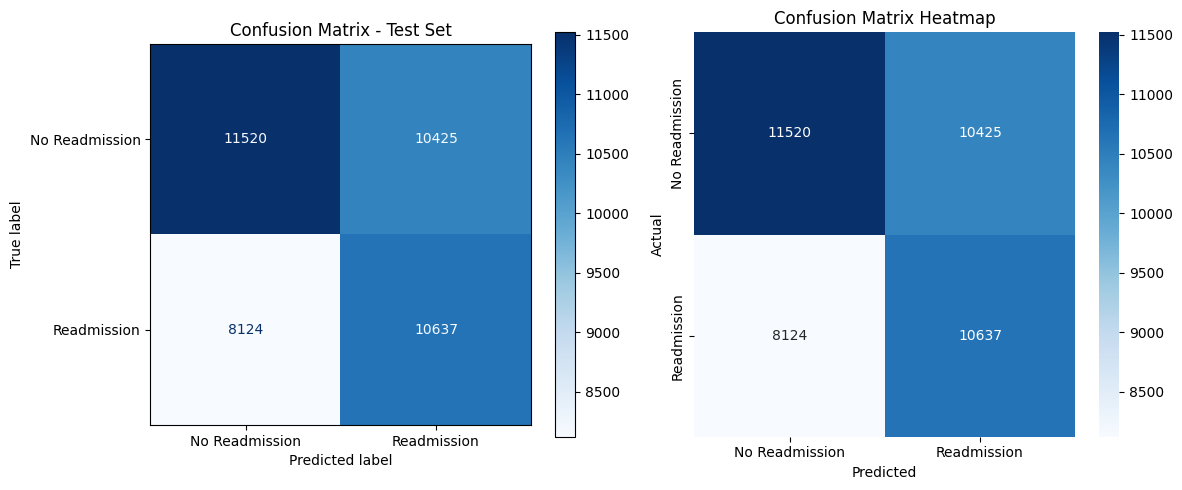

MODEL EVALUATION METRICS

Confusion Matrix:
[[11520 10425]
 [ 8124 10637]]

Classification Report:
                precision    recall  f1-score   support

No Readmission       0.59      0.52      0.55     21945
   Readmission       0.51      0.57      0.53     18761

      accuracy                           0.54     40706
     macro avg       0.55      0.55      0.54     40706
  weighted avg       0.55      0.54      0.54     40706


True Negatives: 11520
False Positives: 10425
False Negatives: 8124
True Positives: 10637
Sensitivity (Recall): 0.5670
Specificity: 0.5249
Precision: 0.5050
F1-Score: 0.5342


In [15]:
# Model Evaluation - Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix for test set
cm = confusion_matrix(y_test, y_pred_test)

# Display confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Using sklearn's ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                              display_labels=['No Readmission', 'Readmission'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix - Test Set')

# Plot 2: Using seaborn heatmap for more customization
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Readmission', 'Readmission'],
            yticklabels=['No Readmission', 'Readmission'],
            ax=axes[1])
axes[1].set_title('Confusion Matrix Heatmap')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

# Print metrics
print("="*50)
print("MODEL EVALUATION METRICS")
print("="*50)
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_test, 
                          target_names=['No Readmission', 'Readmission']))

# Additional metrics
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")
print(f"Sensitivity (Recall): {tp/(tp+fn):.4f}")
print(f"Specificity: {tn/(tn+fp):.4f}")
print(f"Precision: {tp/(tp+fp):.4f}")
print(f"F1-Score: {2*tp/(2*tp+fp+fn):.4f}")

TOP 20 FEATURE IMPORTANCES
                    feature  coefficient  abs_coefficient
30              DiabetesMed     0.368505         0.368505
18                 Acarbose     0.363831         0.363831
7                 Metformin    -0.202274         0.202274
10           Chlorpropamide    -0.186326         0.186326
19                 Miglitol    -0.154670         0.154670
8               Repaglinide     0.151672         0.151672
21               Tolazamide    -0.143960         0.143960
25      Glyburide-metformin    -0.098961         0.098961
14                Glyburide    -0.098496         0.098496
15              Tolbutamide    -0.087837         0.087837
11              Glimepiride    -0.074188         0.074188
26      glipizide-metformin     0.065404         0.065404
1                    Gender    -0.059507         0.059507
17            Rosiglitazone     0.045913         0.045913
24                  Insulin    -0.042348         0.042348
9               Nateglinide     0.040928     

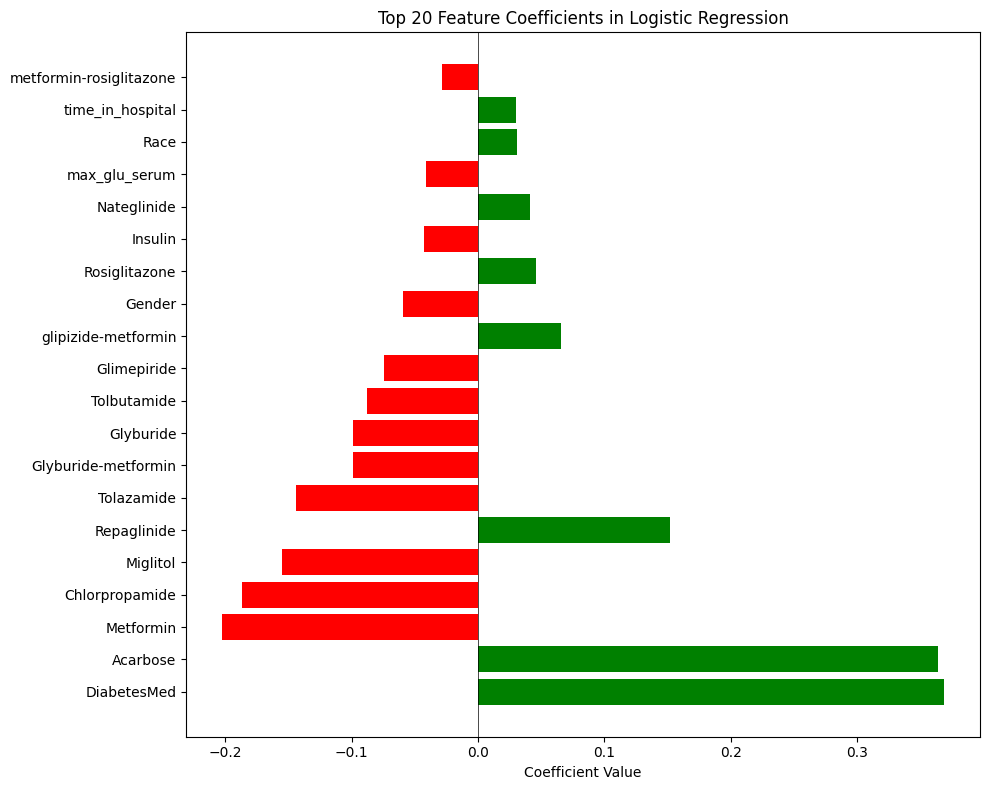

In [16]:
# Feature Importance for Logistic Regression
# Get feature importance from logistic regression
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': logreg.coef_[0]
})
feature_importance['abs_coefficient'] = np.abs(feature_importance['coefficient'])
feature_importance = feature_importance.sort_values('abs_coefficient', ascending=False)

print("="*50)
print("TOP 20 FEATURE IMPORTANCES")
print("="*50)
print(feature_importance.head(20).to_string())

# Plot top features
fig, ax = plt.subplots(figsize=(10, 8))
top_features = feature_importance.head(20)
colors = ['red' if x < 0 else 'green' for x in top_features['coefficient']]
ax.barh(top_features['feature'], top_features['coefficient'], color=colors)
ax.set_xlabel('Coefficient Value')
ax.set_title('Top 20 Feature Coefficients in Logistic Regression')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.show()

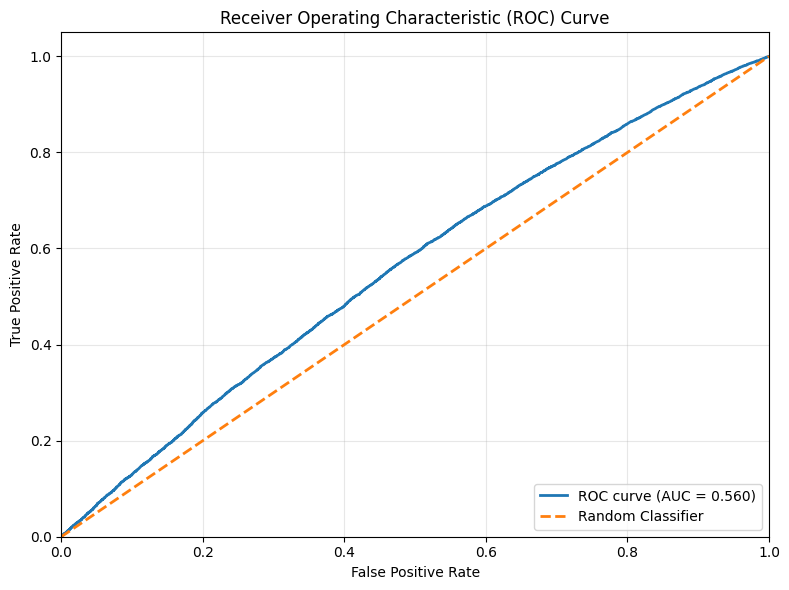

AUC Score: 0.5598
Optimal threshold: 0.4938


In [17]:
# ROC Curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class
# Make sure column 1 corresponds to "Yes"
yes_index = list(logreg.classes_).index('Yes')
y_pred_proba = logreg.predict_proba(X_test)[:, yes_index]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba,
    pos_label='Yes'
)

# Calculate AUC
auc = roc_auc_score(
    y_test,
    y_pred_proba
)

# Plot ROC curve
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    lw=2,
    label=f'ROC curve (AUC = {auc:.3f})'
)

ax.plot(
    [0, 1],
    [0, 1],
    lw=2,
    linestyle='--',
    label='Random Classifier'
)

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Receiver Operating Characteristic (ROC) Curve')
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print AUC
print(f"AUC Score: {auc:.4f}")

# Find optimal threshold using Youden's J statistic
optimal_index = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_index]

print(f"Optimal threshold: {optimal_threshold:.4f}")

In [18]:
import joblib
from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# Calculate AUC before saving
# --------------------------------------------------

# Find the probability column corresponding to "Yes"
yes_index = list(logreg.classes_).index('Yes')

# Get predicted probabilities
y_pred_proba = logreg.predict_proba(X_test)[:, yes_index]

# Calculate AUC
auc = roc_auc_score(
    y_test,
    y_pred_proba
)

print(f"AUC Score: {auc:.4f}")

# --------------------------------------------------
# Prepare model data
# --------------------------------------------------

model_data = {
    'model': logreg,
    'label_encoders': le_dict,
    'feature_names': X.columns.tolist(),
    'accuracy': test_accuracy,
    'auc': auc
}

# --------------------------------------------------
# Save model
# --------------------------------------------------

joblib.dump(
    model_data,
    'logistic_regression_model.pkl'
)

print("Model saved successfully as 'logistic_regression_model.pkl'")

AUC Score: 0.5598
Model saved successfully as 'logistic_regression_model.pkl'
